# High-pressure subsea separation and dense-gas reinjection

**An executable NeqSim screening study inspired by the publicly described HISEP® concept.**

Version **1.0.0**, 1 November 2026. Prepared for Even Solbraa. Public references and a fully declared synthetic fluid are used throughout.

[Open in Google Colab](https://colab.research.google.com/github/EvenSol/NeqSim-Colab/blob/study/hisep-dense-gas-20261101/notebooks/subseaequipment/high_pressure_subsea_separation_dense_gas_reinjection.ipynb)

You will calculate the oil/gas split, gas composition, cooling and boosting duties, residual topside gas load, and conditional facility throughput. You will also see how an excessively high separation pressure can dissolve the gas into one phase and remove the separation opportunity.

This is a steady-state thermodynamic study of a **generic process concept**. It does not reproduce Petrobras or vendor equipment, proprietary controls, pump maps, or Mero production forecasts. HISEP separates associated gas from oil; the bypass gas contains hydrocarbons as well as CO₂.

## 1. Open literature and the engineering question

The public TechnipFMC description [R1] identifies a subsea separator followed by gas scrubbing, cooling, dense-gas pumping and reinjection. Sulzer [R2] describes dedicated dense-gas pumps and reports three 6 MW units for qualification. These equipment ratings are context, not calibration data for this notebook.

The open ROG.e paper [R3] shows that injection composition, GOR restrictions and selection of connected wells affect field-development results. Its published reservoir forecasts are not recreated here. Petrobras described HISEP as under qualification in August 2026 [R4].

**Question:** for the same wellstream, how much gas can bypass topside processing, at what conditioning/boosting duty, and how does that change a declared facility-capacity screen?

| Route | Sequence | Material leaving the process boundary |
|---|---|---|
| Topside reference | Whole wellstream → 40 bara / 40°C separation → 10 bara / 40°C separation; separated gases recompressed | Oil at 10 bara / 40°C; total reinjection fluid at 300 bara / 30°C |
| Subsea concept | 150 bara / 80°C separation; bypass gas cooled to 25°C and boosted; residual oil follows the same topside train | Oil at 10 bara / 40°C; bypass and topside gases combined at 300 bara / 30°C |

**Boundary:** processing duties are compared with a common pressure/temperature target, at a common reference elevation. Production risers, injection flowlines, downhole hydrostatics, friction and reservoir injectivity are excluded. Therefore the calculated power difference is a processing-block result, not a complete field electrical-load or emissions forecast.

## 2. Clean Colab setup and immutable runtime provenance

The source revision below was current `equinor/neqsim` master when this notebook was prepared. A normal Colab run clones that revision and builds the Java runtime. The released Python package is not used as the calculation engine.

Local qualification can supply `NEQSIM_AUDITED_SOURCE_MANIFEST`: every Java/resource Git blob and the source-built runtime JAR are checked before use. This supports a connector-materialized source snapshot without inventing a Git checkout. A fresh Python process is required when changing a Java runtime.

In [1]:
import hashlib
import importlib.metadata
import importlib.util
import json
import os
from pathlib import Path
import subprocess
import sys
from urllib.parse import unquote, urlparse

NEQSIM_SOURCE_REF = "a049b0c147a7dc27999f4182fe8f7c5041614daa"
NEQSIM_REPOSITORY = "https://github.com/equinor/neqsim.git"
os.environ["NEQSIM_JVM_AUTOSTART"] = "0"

required_packages = {
    "jpype": "JPype1==1.7.1",
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "CoolProp": "CoolProp",
}
missing_packages = []
for module_name, package_spec in required_packages.items():
    if importlib.util.find_spec(module_name) is None:
        missing_packages.append(package_spec)
if missing_packages:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "--quiet", *missing_packages],
        check=True,
    )

import jpype
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from CoolProp.CoolProp import PropsSI

manifest_path = os.environ.get("NEQSIM_AUDITED_SOURCE_MANIFEST")
if manifest_path:
    manifest_file = Path(manifest_path).resolve()
    provenance = json.loads(manifest_file.read_text())
    source_root = manifest_file.parent
    source_sha = provenance["source_commit"]
    assert source_sha == NEQSIM_SOURCE_REF
    assert provenance["all_git_blobs_verified"]
    for item in provenance["files"]:
        source_bytes = (source_root / item["path"]).read_bytes()
        git_header = f"blob {len(source_bytes)}\0".encode("ascii")
        blob_sha = hashlib.sha1(git_header + source_bytes).hexdigest()
        assert blob_sha == item["sha"], item["path"]
    source_jar = Path(provenance["jar_path"]).resolve()
    build_method = provenance["method"]
else:
    source_root = Path("neqsim-hisep-source").resolve()
    if not source_root.exists():
        subprocess.run(
            ["git", "clone", "--depth", "1", NEQSIM_REPOSITORY, str(source_root)],
            check=True,
            capture_output=True,
            text=True,
        )
    subprocess.run(
        ["git", "fetch", "--depth", "1", "origin", NEQSIM_SOURCE_REF],
        cwd=source_root,
        check=True,
        capture_output=True,
        text=True,
    )
    subprocess.run(
        ["git", "checkout", "--detach", NEQSIM_SOURCE_REF],
        cwd=source_root,
        check=True,
        capture_output=True,
        text=True,
    )
    source_sha = subprocess.check_output(
        ["git", "rev-parse", "HEAD"], cwd=source_root, text=True
    ).strip()
    assert source_sha == NEQSIM_SOURCE_REF
    subprocess.run(
        [
            "bash", "mvnw", "-q", "-DskipTests", "-Dmaven.test.skip=true",
            "-Dspotless.skip=true", "-Dcheckstyle.skip", "-Dmaven.javadoc.skip=true",
            "package",
        ],
        cwd=source_root,
        check=True,
        capture_output=True,
        text=True,
    )
    jar_candidates = [
        candidate for candidate in (source_root / "target").glob("neqsim-*.jar")
        if not any(label in candidate.name for label in ("sources", "javadoc", "original"))
    ]
    source_jar = max(jar_candidates, key=lambda candidate: candidate.stat().st_size)
    build_method = "Pinned Git checkout; Maven source build"

jar_sha256 = hashlib.sha256(source_jar.read_bytes()).hexdigest()
if manifest_path:
    assert jar_sha256 == provenance["jar_sha256"]
assert not jpype.isJVMStarted(), "Restart the Python runtime before selecting this JAR"
jpype.addClassPath(str(source_jar))
jpype.startJVM("-Xrs", "-Xmx2g", convertStrings=True)

class_names = {
    "SystemPrEos": "neqsim.thermo.system.SystemPrEos",
    "SystemSrkEos": "neqsim.thermo.system.SystemSrkEos",
    "ThermodynamicOperations": "neqsim.thermodynamicoperations.ThermodynamicOperations",
    "Stream": "neqsim.process.equipment.stream.Stream",
    "Heater": "neqsim.process.equipment.heatexchanger.Heater",
    "Cooler": "neqsim.process.equipment.heatexchanger.Cooler",
    "Separator": "neqsim.process.equipment.separator.Separator",
    "Pump": "neqsim.process.equipment.pump.Pump",
    "Compressor": "neqsim.process.equipment.compressor.Compressor",
    "Mixer": "neqsim.process.equipment.mixer.Mixer",
    "ProcessSystem": "neqsim.process.processmodel.ProcessSystem",
    "SubseaSeparationStation": "neqsim.process.equipment.subsea.SubseaSeparationStation",
}
for short_name, full_name in class_names.items():
    java_class = jpype.JClass(full_name)
    globals()[short_name] = java_class
    origin = str(java_class.class_.getProtectionDomain().getCodeSource().getLocation())
    loaded_path = Path(unquote(urlparse(origin).path)).resolve()
    assert loaded_path == source_jar

plt.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.grid": True})
pd.set_option("display.max_rows", 40)
pd.set_option("display.max_columns", 12)
print("NeqSim source commit:", source_sha)
print("Source-built JAR SHA-256:", jar_sha256)
print("Source verification/build:", build_method)
print("Class origin:", origin)
print("Python:", sys.version.split()[0])
print("Java:", jpype.java.lang.System.getProperty("java.version"))
print("Packages:", {
    name: importlib.metadata.version(name)
    for name in ("JPype1", "numpy", "pandas", "matplotlib", "CoolProp")
})

NeqSim source commit: a049b0c147a7dc27999f4182fe8f7c5041614daa
Source-built JAR SHA-256: cf841ef2adac9e7ad2ef369b345f472f5a3019afb42700ed1a6ced40e407932d
Source verification/build: All current Java source compiled with Eclipse ECJ 3.40.0, Java 8 target; current resources overlaid; released shaded JAR supplies third-party dependencies
Class origin: file:/workspace/scratch/f033e0b6f467/source/target/neqsim-master-a049b0c.jar
Python: 3.12.14
Java: 17.0.20
Packages: {'JPype1': '1.7.1', 'numpy': '2.5.4', 'pandas': '3.1.0', 'matplotlib': '3.11.2', 'CoolProp': '8.0.0'}


## 3. Declared synthetic fluid and operating assumptions

The dry feed contains **45 mol% CO₂**, light hydrocarbons and two explicit heavy hydrocarbons. It is a teaching mixture, not a Mero, Bacalhau or measured crude-oil assay. The heavy components are individual normal alkanes; there is no fitted C₇₊ characterization. Volume correction is explicitly disabled so the reported density is consistent with the untranslated cubic EOS used for the work-integral check.

The model uses Peng–Robinson with NeqSim's `classic` mixing rule and database interaction parameters. The SRK sensitivity below is a model-form comparison, not validation of either EOS against this unmeasured fluid. All pressures are **absolute**. All process rates use kg/s; standard gas volumes are avoided in the capacity calculation.

The default hot separation point is deliberately synthetic. The pressure sweep explores phase disappearance rather than assuming a fixed gas-removal fraction. Water, salts, solids, emulsions and separation kinetics are outside the dry-fluid calculation. Actual cooling and reinjection require water management and hydrate/corrosion assessments.

In [2]:
COMPOSITION = {
    "CO2": 0.450,
    "methane": 0.350,
    "ethane": 0.040,
    "propane": 0.030,
    "i-butane": 0.010,
    "n-butane": 0.010,
    "n-pentane": 0.010,
    "n-hexane": 0.010,
    "n-decane": 0.025,
    "n-hexadecane": 0.065,
}
CASE = {
    "feed_kg_s": 50.0,
    "subsea_pressure_bara": 150.0,
    "subsea_temperature_C": 80.0,
    "bypass_cooler_C": 25.0,
    "injection_pressure_bara": 300.0,
    "injection_temperature_C": 30.0,
    "topside_stage_pressures_bara": (40.0, 10.0),
    "topside_temperature_C": 40.0,
    "intercooler_temperature_C": 60.0,
    "isentropic_efficiency": 0.75,
    "motor_efficiency": 0.97,
}
assert np.isclose(sum(COMPOSITION.values()), 1.0)
display(pd.DataFrame({"component": COMPOSITION.keys(), "mole_fraction": COMPOSITION.values()}))
display(pd.DataFrame({"assumption": CASE.keys(), "value": map(str, CASE.values())}))

,component,mole_fraction
0,CO2,0.450
1,methane,0.350
2,ethane,0.040
3,propane,0.030
4,i-butane,0.010
5,n-butane,0.010
6,n-pentane,0.010
7,n-hexane,0.010
8,n-decane,0.025
9,n-hexadecane,0.065


,assumption,value
0,feed_kg_s,50.0
1,subsea_pressure_bara,150.0
2,subsea_temperature_C,80.0
3,bypass_cooler_C,25.0
4,injection_pressure_bara,300.0
5,injection_temperature_C,30.0
6,topside_stage_pressures_bara,"(40.0, 10.0)"
7,topside_temperature_C,40.0
8,intercooler_temperature_C,60.0
9,isentropic_efficiency,0.75


## 4. Reusable native NeqSim model

Every equipment object belongs to a `ProcessSystem`; named streams and both complete process objects are retained. The generic `Separator` is used to expose the bypass gas explicitly. Existing `SubseaSeparationStation` can supply a three-phase/liquid-boosting extension, while dense-gas boosting is added here through the native `Pump` isentropic mode.

A dense-gas pump uses compressible-fluid thermodynamics. Its duty is calculated from the EOS isentropic enthalpy rise, not a constant-density liquid approximation:

$$W_s=\frac{\dot m\left(h_{2s}-h_1\right)}{\eta_s}$$

Here $W_s$ is shaft power in W, $\dot m$ is mass flow in kg/s, $h$ is specific enthalpy in J/kg, and $\eta_s$ is isentropic efficiency. Subscript $2s$ denotes the outlet at inlet entropy and specified outlet pressure. Motor electrical power is $W_s/\eta_m$.

The topside reference uses pressure ratios no larger than three per compressor stage, with 60°C intercooling. Phase checks reject a multiphase compressor inlet. Separator performance is ideal equilibrium; no equipment-rating or entrainment performance is inferred.

In [3]:
def make_fluid(temperature_C, pressure_bara, composition=None, eos="PR"):
    composition = COMPOSITION if composition is None else composition
    fluid_class = SystemPrEos if eos == "PR" else SystemSrkEos
    fluid = fluid_class(float(temperature_C + 273.15), float(pressure_bara))
    for component, fraction in composition.items():
        fluid.addComponent(component, float(fraction))
    fluid.setMixingRule("classic")
    fluid.useVolumeCorrection(False)
    return fluid


def add_run(process, unit):
    unit.run()
    process.add(unit)
    return unit


def material_rates(stream):
    fluid = stream.getFluid()
    molar_rate = float(stream.getFlowRate("mol/sec"))
    return np.array([
        molar_rate * fluid.getPhase(0).getComponent(component).getz()
        for component in COMPOSITION
    ])


def enthalpy_rate(stream):
    stream.getFluid().init(3)
    return float(stream.getFluid().getEnthalpy())


def thermal_condition(process, ledger, name, inlet, pressure_bara, temperature_C):
    unit = Heater(name, inlet)
    unit.setOutPressure(float(pressure_bara))
    unit.setOutTemperature(float(temperature_C + 273.15))
    add_run(process, unit)
    outlet = unit.getOutletStream()
    ledger.append({
        "unit": name,
        "heat_W": enthalpy_rate(outlet) - enthalpy_rate(inlet),
        "shaft_W": 0.0,
    })
    return outlet


def compress_gas(process, ledger, inlet, target_bara, prefix, efficiency, intercooler_C):
    current = inlet
    inlet_pressure = float(current.getPressure("bara"))
    stage_count = max(1, int(np.ceil(np.log(target_bara / inlet_pressure) / np.log(3.0))))
    pressure_steps = np.geomspace(inlet_pressure, target_bara, stage_count + 1)[1:]
    for stage, pressure_bara in enumerate(pressure_steps, start=1):
        assert int(current.getFluid().getNumberOfPhases()) == 1, prefix
        compressor = Compressor(f"{prefix} compressor {stage}", current)
        compressor.setOutletPressure(float(pressure_bara))
        compressor.setIsentropicEfficiency(float(efficiency))
        compressor.setUsePolytropicCalc(False)
        add_run(process, compressor)
        ledger.append({
            "unit": compressor.getName(),
            "heat_W": 0.0,
            "shaft_W": float(compressor.getPower("W")),
        })
        current = thermal_condition(
            process, ledger, f"{prefix} intercooler {stage}",
            compressor.getOutletStream(), float(pressure_bara),
            intercooler_C,
        )
    return current


def build_process(use_subsea, case=None, eos="PR"):
    settings = dict(CASE if case is None else case)
    label = "Subsea concept" if use_subsea else "Topside reference"
    process = ProcessSystem()
    ledger = []
    fluid = make_fluid(
        settings["subsea_temperature_C"], settings["subsea_pressure_bara"], eos=eos
    )
    feed = Stream(f"{label} feed", fluid)
    feed.setFlowRate(float(settings["feed_kg_s"]), "kg/sec")
    add_run(process, feed)
    host_feed = feed
    injection_streams = []
    bypass_gas = None
    pump = None
    pump_inlet = None
    if use_subsea:
        subsea_separator = add_run(process, Separator("Subsea HP separator", feed))
        bypass_gas = subsea_separator.getGasOutStream()
        host_feed = subsea_separator.getLiquidOutStream()
        assert bypass_gas.getFlowRate("kg/sec") > 0.0
        pump_inlet = thermal_condition(
            process, ledger, "Subsea bypass cooler", bypass_gas,
            settings["subsea_pressure_bara"], settings["bypass_cooler_C"],
        )
        pump_inlet.getFluid().initProperties()
        assert int(pump_inlet.getFluid().getNumberOfPhases()) == 1
        pump = Pump("Dense-gas reinjection pump", pump_inlet)
        pump.calculateAsCompressor(True)
        pump.setOutletPressure(float(settings["injection_pressure_bara"]))
        pump.setIsentropicEfficiency(float(settings["isentropic_efficiency"]))
        add_run(process, pump)
        ledger.append({
            "unit": pump.getName(), "heat_W": 0.0,
            "shaft_W": float(pump.getPower("W")),
        })
        injection_streams.append(pump.getOutletStream())
    host_gases = []
    oil = host_feed
    for stage, pressure_bara in enumerate(settings["topside_stage_pressures_bara"], start=1):
        conditioned = thermal_condition(
            process, ledger, f"Topside stage {stage} pressure/temperature control",
            oil, pressure_bara, settings["topside_temperature_C"],
        )
        separator = add_run(process, Separator(f"Topside separator {stage}", conditioned))
        gas = separator.getGasOutStream()
        host_gases.append(gas)
        oil = separator.getLiquidOutStream()
        injection_streams.append(compress_gas(
            process, ledger, gas, settings["injection_pressure_bara"],
            f"Topside gas {stage}", settings["isentropic_efficiency"],
            settings["intercooler_temperature_C"],
        ))
    injection_mixer = Mixer("Combined reinjection fluid")
    for injection_stream in injection_streams:
        injection_mixer.addStream(injection_stream)
    add_run(process, injection_mixer)
    injection = thermal_condition(
        process, ledger, "Final reinjection cooler", injection_mixer.getOutletStream(),
        settings["injection_pressure_bara"], settings["injection_temperature_C"],
    )
    process.run()
    return {
        "name": label, "process": process, "feed": feed, "oil": oil,
        "injection": injection, "host_gases": host_gases, "bypass_gas": bypass_gas,
        "pump": pump, "pump_inlet": pump_inlet, "ledger": pd.DataFrame(ledger),
        "settings": settings,
    }


def summarize(result):
    ledger = result["ledger"]
    bypass = result["bypass_gas"]
    feed_components = material_rates(result["feed"])
    bypass_components = np.zeros(len(COMPOSITION)) if bypass is None else material_rates(bypass)
    co2_index = list(COMPOSITION).index("CO2")
    return {
        "case": result["name"],
        "feed_kg_s": result["feed"].getFlowRate("kg/sec"),
        "host_gas_kg_s": sum(stream.getFlowRate("kg/sec") for stream in result["host_gases"]),
        "bypass_kg_s": 0.0 if bypass is None else bypass.getFlowRate("kg/sec"),
        "oil_product_kg_s": result["oil"].getFlowRate("kg/sec"),
        "reinjection_kg_s": result["injection"].getFlowRate("kg/sec"),
        "CO2_bypass_fraction": bypass_components[co2_index] / feed_components[co2_index],
        "shaft_MW": ledger["shaft_W"].sum() / 1e6,
        "electrical_MW": ledger["shaft_W"].sum() / result["settings"]["motor_efficiency"] / 1e6,
        "cooling_MW": -ledger.loc[ledger["heat_W"] < 0.0, "heat_W"].sum() / 1e6,
        "heating_MW": ledger.loc[ledger["heat_W"] > 0.0, "heat_W"].sum() / 1e6,
    }

reference = build_process(False)
subsea = build_process(True)
results = [reference, subsea]
summary = pd.DataFrame([summarize(result) for result in results]).set_index("case")
display(summary.transpose().round(5))

case,Topside reference,Subsea concept
feed_kg_s,50.00000,50.00000
host_gas_kg_s,28.56511,10.62713
bypass_kg_s,0.00000,18.60624
oil_product_kg_s,21.43489,20.76663
reinjection_kg_s,28.56511,29.23337
CO2_bypass_fraction,0.00000,0.59579
shaft_MW,6.18491,3.24536
electrical_MW,6.37620,3.34574
cooling_MW,13.04584,10.14743
heating_MW,0.57802,0.60601


## 5. Stream states, component accounting and energy closure

The oil product is the liquid leaving **10 bara / 40°C**. It is neither a stock-tank volume nor a stabilized export specification. Gas retained in that liquid remains inside the material boundary.

The overall component check is:

$$\dot n_{i,feed}=\dot n_{i,oil}+\dot n_{i,reinjection}$$

For every component $i$, $\dot n_i$ is its molar rate in mol/s. All gas is reinjected in both cases; the subsea concept changes its processing route and the partitioning of hydrocarbons, rather than treating all bypass gas as pure CO₂ capture.

The energy ledger uses positive heat into the fluid and positive shaft work into the fluid:

$$R_E=H_{out}-H_{in}-Q-W_s$$

$H$, $Q$, $W_s$ and the residual $R_E$ are rates in W. Heating/cooling entries represent combined pressure reduction and temperature control where applicable. Riser potential energy is outside this balance.

In [4]:
def stream_record(name, stream):
    fluid = stream.getFluid()
    fluid.initProperties()
    return {
        "stream": name,
        "mass_kg_s": stream.getFlowRate("kg/sec"),
        "pressure_bara": stream.getPressure("bara"),
        "temperature_C": stream.getTemperature("C"),
        "phases": fluid.getNumberOfPhases(),
        "density_kg_m3": fluid.getDensity("kg/m3"),
        "CO2_mol_fraction": fluid.getPhase(0).getComponent("CO2").getz(),
    }

stream_rows = []
validation_rows = []
for result in results:
    for label, stream in (("feed", result["feed"]), ("oil", result["oil"]),
                          ("reinjection", result["injection"])):
        stream_rows.append(stream_record(f"{result['name']}: {label}", stream))
    feed_components = material_rates(result["feed"])
    outlet_components = material_rates(result["oil"]) + material_rates(result["injection"])
    component_error = np.max(np.abs(outlet_components - feed_components))
    mass_error = (
        result["oil"].getFlowRate("kg/sec")
        + result["injection"].getFlowRate("kg/sec")
        - result["feed"].getFlowRate("kg/sec")
    )
    net_heat = result["ledger"]["heat_W"].sum()
    shaft_work = result["ledger"]["shaft_W"].sum()
    energy_error = (
        enthalpy_rate(result["oil"]) + enthalpy_rate(result["injection"])
        - enthalpy_rate(result["feed"]) - net_heat - shaft_work
    )
    validation_rows.append({
        "case": result["name"], "mass_residual_kg_s": mass_error,
        "max_component_residual_mol_s": component_error,
        "energy_residual_W": energy_error,
    })
    assert result["injection"].getFluid().getNumberOfPhases() == 1
    assert np.isclose(result["injection"].getPressure("bara"), 300.0)
    assert np.isclose(result["injection"].getTemperature("C"), 30.0)
    assert shaft_work > 0.0
    assert abs(mass_error) < 1e-7
    assert component_error < 1e-6
    assert abs(energy_error) < max(5.0, abs(shaft_work) * 1e-5)

stream_table = pd.DataFrame(stream_rows)
validation_table = pd.DataFrame(validation_rows)
display(stream_table.round(5))
display(validation_table)
print("PASS: total mass, every component, and process energy closure")

PASS: total mass, every component, and process energy closure


,stream,mass_kg_s,pressure_bara,temperature_C,phases,density_kg_m3,CO2_mol_fraction
0,Topside reference: feed,50.00000,150.0,80.0,2,366.31034,0.45000
1,Topside reference: oil,21.43489,10.0,40.0,1,643.20785,0.09562
2,Topside reference: reinjection,28.56511,300.0,30.0,1,549.83909,0.50673
3,Subsea concept: feed,50.00000,150.0,80.0,2,366.31034,0.45000
4,Subsea concept: oil,20.76663,10.0,40.0,1,643.43154,0.10012
5,Subsea concept: reinjection,29.23337,300.0,30.0,1,556.09486,0.50329


,case,mass_residual_kg_s,max_component_residual_mol_s,energy_residual_W
0,Topside reference,4.263256e-14,5.684342e-14,-1.862645e-09
1,Subsea concept,1.299298e-10,5.092176e-10,-4.190952e-09


,component,feed_mol_s,subsea_reinjection_mol_s,remaining_for_topside_mol_s,fraction_bypassed
0,CO2,459.52020,273.77878,185.74142,0.59579
1,methane,357.40460,249.43293,107.97167,0.69790
2,ethane,40.84624,22.77097,18.07527,0.55748
3,propane,30.63468,13.89354,16.74114,0.45352
4,i-butane,10.21156,3.93523,6.27633,0.38537
5,n-butane,10.21156,3.62407,6.58749,0.35490
6,n-pentane,10.21156,2.78524,7.42632,0.27275
7,n-hexane,10.21156,2.10486,8.10670,0.20612
8,n-decane,25.52890,1.56970,23.95920,0.06149
9,n-hexadecane,66.37514,0.94143,65.43371,0.01418


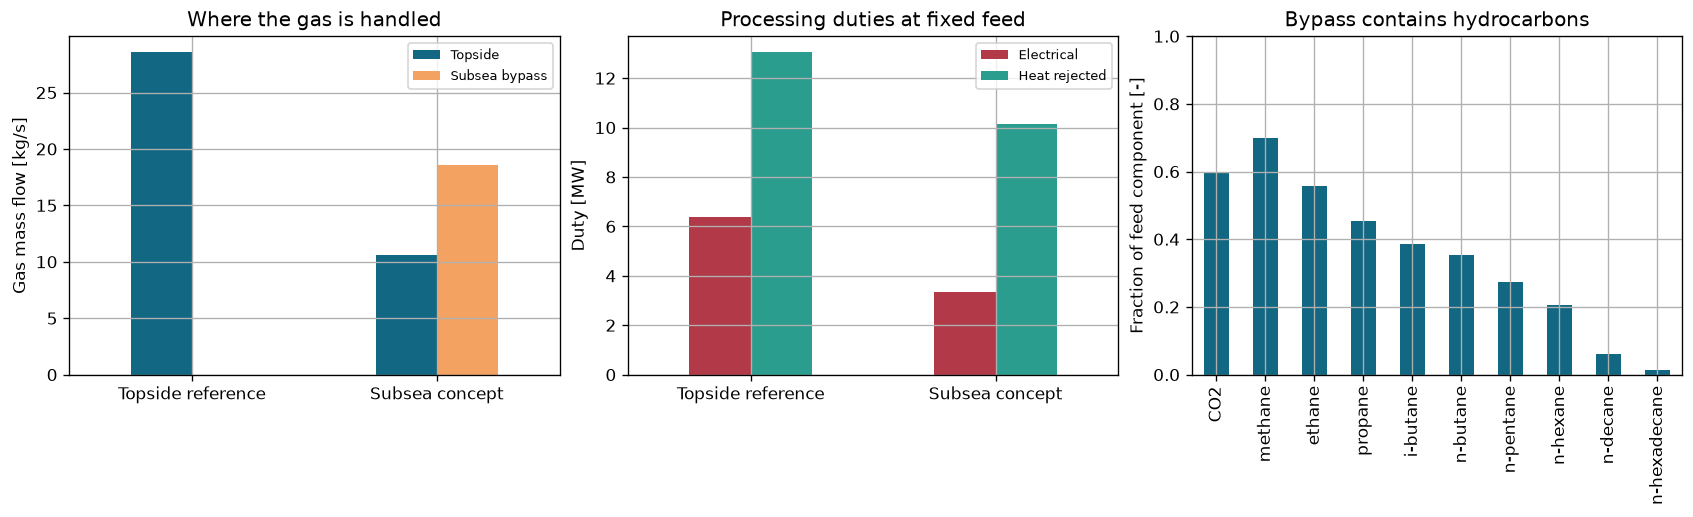

In [5]:
bypass_components = material_rates(subsea["bypass_gas"])
feed_components = material_rates(subsea["feed"])
partition_table = pd.DataFrame({
    "component": COMPOSITION.keys(),
    "feed_mol_s": feed_components,
    "subsea_reinjection_mol_s": bypass_components,
    "remaining_for_topside_mol_s": feed_components - bypass_components,
    "fraction_bypassed": bypass_components / feed_components,
})
display(partition_table.round(5))

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), constrained_layout=True)
summary[["host_gas_kg_s", "bypass_kg_s"]].plot.bar(
    ax=axes[0], rot=0, color=["#126782", "#f4a261"]
)
axes[0].set_ylabel("Gas mass flow [kg/s]")
axes[0].set_xlabel("")
axes[0].set_title("Where the gas is handled")
axes[0].legend(["Topside", "Subsea bypass"], fontsize=8)
summary[["electrical_MW", "cooling_MW"]].plot.bar(
    ax=axes[1], rot=0, color=["#b23a48", "#2a9d8f"]
)
axes[1].set_ylabel("Duty [MW]")
axes[1].set_xlabel("")
axes[1].set_title("Processing duties at fixed feed")
axes[1].legend(["Electrical", "Heat rejected"], fontsize=8)
partition_table.set_index("component")["fraction_bypassed"].plot.bar(
    ax=axes[2], color="#126782"
)
axes[2].set_ylabel("Fraction of feed component [-]")
axes[2].set_xlabel("")
axes[2].set_ylim(0, 1)
axes[2].set_title("Bypass contains hydrocarbons")
plt.show()

## 6. Separation pressure and temperature: more pressure does not guarantee more bypass

The next calculation flashes the **same feed composition** over pressure at three temperatures. A single-phase point is retained as a valid thermodynamic result and assigned zero gas bypass. It is not forced into a two-phase split.

Phase labels are NeqSim EOS labels. Near critical regions a liquid-like density can belong to a fluid historically called a gas stream; the key operating checks are phase stability, density, compressibility and the equipment map. No universal density threshold certifies pump suitability.

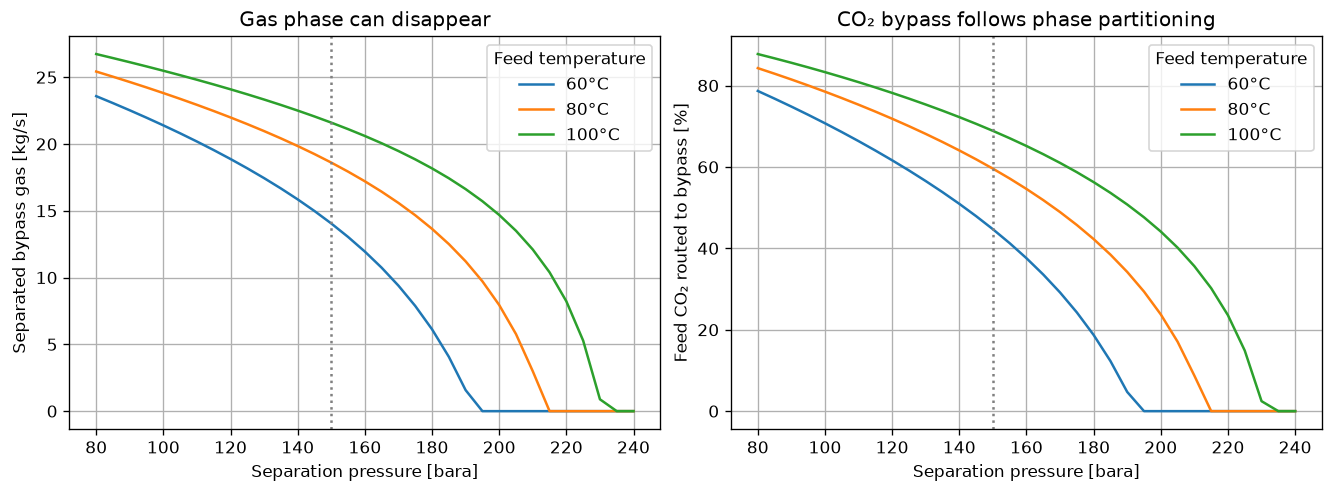

,pressure_bara,temperature_C,eos,phases,gas_mass_kg_s,gas_molar_fraction,CO2_bypass_fraction
0,80.0,60.0,PR,2,23.5793,0.7237,0.7866
8,120.0,60.0,PR,2,18.8736,0.5846,0.6163
16,160.0,60.0,PR,2,11.9437,0.3679,0.3757
24,200.0,60.0,PR,1,0.0000,0.0000,0.0000
32,240.0,60.0,PR,1,0.0000,0.0000,0.0000
40,115.0,80.0,PR,2,22.4663,0.6822,0.7360
48,155.0,80.0,PR,2,17.9293,0.5416,0.5716
56,195.0,80.0,PR,2,9.7192,0.2850,0.2937
64,235.0,80.0,PR,1,0.0000,0.0000,0.0000
72,110.0,100.0,PR,2,24.8074,0.7417,0.8083


In [6]:
def phase_split_point(pressure_bara, temperature_C, eos="PR"):
    fluid = make_fluid(temperature_C, pressure_bara, eos=eos)
    fluid.setTotalFlowRate(CASE["feed_kg_s"], "kg/sec")
    ThermodynamicOperations(fluid).TPflash()
    fluid.initProperties()
    gas_mass = 0.0
    gas_molar = 0.0
    co2_molar = 0.0
    if fluid.getNumberOfPhases() > 1:
        for phase_index in range(fluid.getNumberOfPhases()):
            phase = fluid.getPhase(phase_index)
            if str(phase.getPhaseTypeName()) == "gas":
                gas_molar = float(phase.getNumberOfMolesInPhase())
                gas_mass = gas_molar * phase.getMolarMass()
                co2_molar = gas_molar * phase.getComponent("CO2").getx()
    total_molar = float(fluid.getTotalNumberOfMoles())
    return {
        "pressure_bara": pressure_bara, "temperature_C": temperature_C,
        "eos": eos, "phases": int(fluid.getNumberOfPhases()),
        "gas_mass_kg_s": gas_mass, "gas_molar_fraction": gas_molar / total_molar,
        "CO2_bypass_fraction": co2_molar / (total_molar * COMPOSITION["CO2"]),
    }

pressure_points = np.linspace(80.0, 240.0, 33)
separation_sweep = pd.DataFrame(
    phase_split_point(float(pressure), temperature)
    for temperature in (60.0, 80.0, 100.0)
    for pressure in pressure_points
)
assert ((separation_sweep["gas_molar_fraction"] >= 0.0)
        & (separation_sweep["gas_molar_fraction"] <= 1.0)).all()
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for temperature, group in separation_sweep.groupby("temperature_C"):
    axes[0].plot(group["pressure_bara"], group["gas_mass_kg_s"], label=f"{temperature:g}°C")
    axes[1].plot(
        group["pressure_bara"], 100 * group["CO2_bypass_fraction"],
        label=f"{temperature:g}°C",
    )
for axis in axes:
    axis.axvline(CASE["subsea_pressure_bara"], color="0.5", linestyle=":")
    axis.set_xlabel("Separation pressure [bara]")
    axis.legend(title="Feed temperature")
axes[0].set_ylabel("Separated bypass gas [kg/s]")
axes[1].set_ylabel("Feed CO₂ routed to bypass [%]")
axes[0].set_title("Gas phase can disappear")
axes[1].set_title("CO₂ bypass follows phase partitioning")
plt.show()
display(separation_sweep.iloc[::8].round(4))

## 7. Cooling and dense-fluid boosting

This map keeps the **default separated-gas composition** fixed and varies conditioning pressure and temperature. It is a property map, not a complete separator redesign. Two-phase states are masked rather than silently treated as pumpable single-phase gas.

The incompressible estimate is included only as a screening comparison:

$$W_{inc}=\frac{\dot m\Delta p}{\rho_1\eta_s}$$

Here $\Delta p$ is in Pa and inlet density $\rho_1$ is in kg/m³. For a compressible dense fluid, density changes along the pressure path can materially change duty.

Two-phase grid points excluded from the density contour: 53
Default bypass inlet density [kg/m³]: 380.335


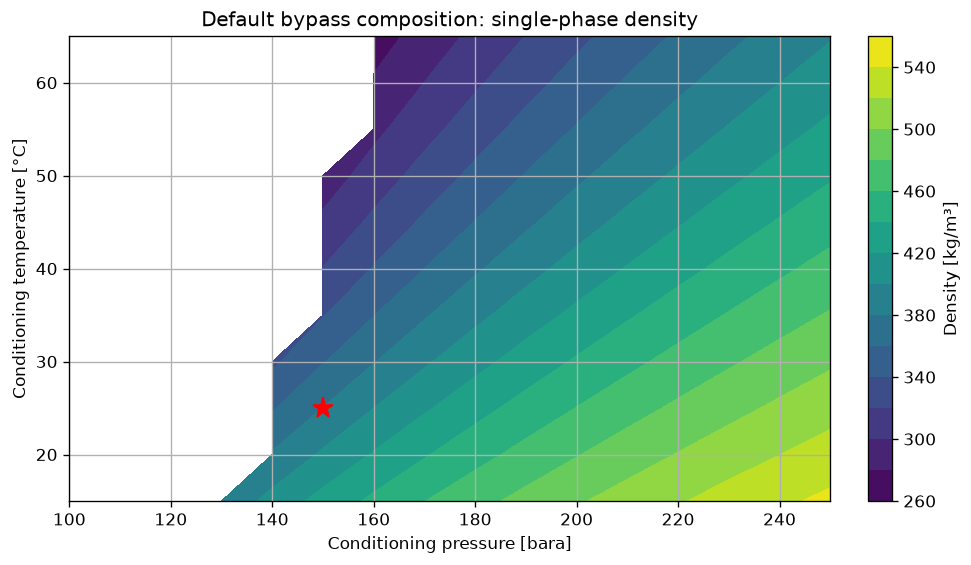

In [7]:
cooled_gas_composition = {
    component: float(subsea["bypass_gas"].getFluid().getPhase(0).getComponent(component).getz())
    for component in COMPOSITION
}
map_pressures = np.linspace(100.0, 250.0, 16)
map_temperatures = np.linspace(15.0, 65.0, 11)
density_map = np.full((len(map_temperatures), len(map_pressures)), np.nan)
phase_count_map = np.zeros_like(density_map)
for row, temperature in enumerate(map_temperatures):
    for column, pressure in enumerate(map_pressures):
        fluid = make_fluid(float(temperature), float(pressure), cooled_gas_composition)
        ThermodynamicOperations(fluid).TPflash()
        fluid.initProperties()
        phase_count_map[row, column] = fluid.getNumberOfPhases()
        if fluid.getNumberOfPhases() == 1:
            density_map[row, column] = fluid.getDensity("kg/m3")

fig, axis = plt.subplots(figsize=(8, 4.6), constrained_layout=True)
contour = axis.contourf(map_pressures, map_temperatures, density_map, levels=14, cmap="viridis")
axis.plot(CASE["subsea_pressure_bara"], CASE["bypass_cooler_C"], "r*", ms=13)
axis.set_xlabel("Conditioning pressure [bara]")
axis.set_ylabel("Conditioning temperature [°C]")
axis.set_title("Default bypass composition: single-phase density")
fig.colorbar(contour, ax=axis, label="Density [kg/m³]")
plt.show()
print("Two-phase grid points excluded from the density contour:", int((phase_count_map > 1).sum()))
print("Default bypass inlet density [kg/m³]:",
      round(subsea["pump_inlet"].getFluid().getDensity("kg/m3"), 3))

PASS: isentropic integral/enthalpy relative difference: 2.7573574117312205e-06
PASS: native pump/isentropic enthalpy relative difference: 1.1102230246251565e-15


,method,shaft_kW
0,Native compressible pump,873.1491
1,Isentropic v dp integral / efficiency,873.1515
2,Constant inlet-density estimate,978.4130


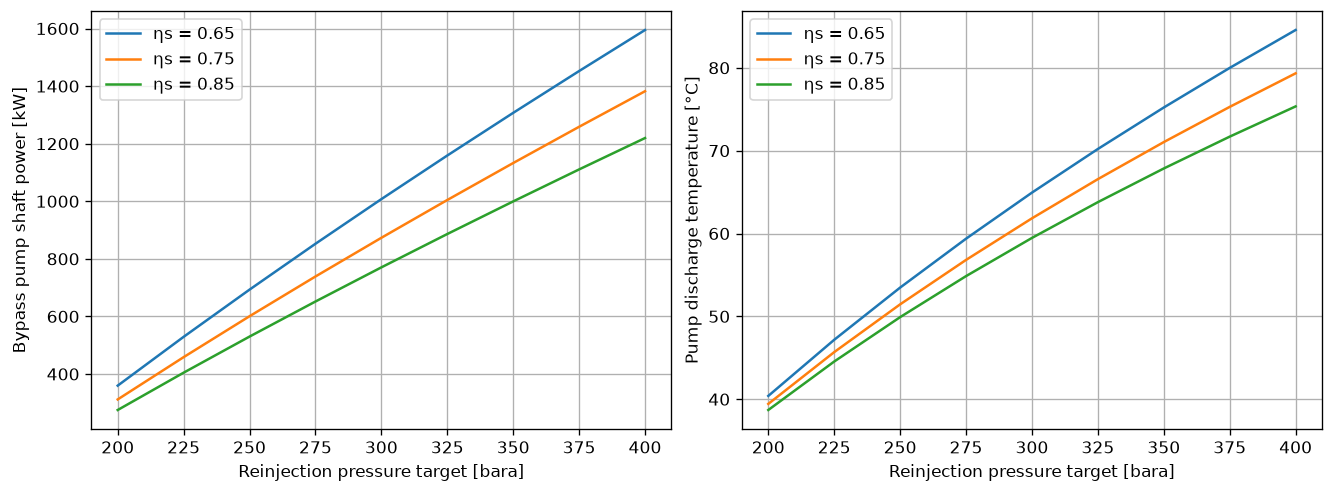

In [8]:
pump_inlet = subsea["pump_inlet"]
inlet_fluid = pump_inlet.getFluid()
inlet_fluid.initProperties()
inlet_pressure = pump_inlet.getPressure("bara")
mass_rate = pump_inlet.getFlowRate("kg/sec")
inlet_density = inlet_fluid.getDensity("kg/m3")
inlet_entropy = inlet_fluid.getEntropy()
inlet_enthalpy = inlet_fluid.getEnthalpy()
pressure_path = np.linspace(inlet_pressure, CASE["injection_pressure_bara"], 81)
inverse_density_path = []
for pressure in pressure_path:
    state = inlet_fluid.clone()
    state.setPressure(float(pressure))
    ThermodynamicOperations(state).PSflash(float(inlet_entropy))
    state.initProperties()
    assert state.getNumberOfPhases() == 1
    inverse_density_path.append(1.0 / state.getDensity("kg/m3"))
specific_volumes = np.array(inverse_density_path)
mean_specific_volumes = 0.5 * (specific_volumes[1:] + specific_volumes[:-1])
isentropic_integral_W = mass_rate * np.sum(
    mean_specific_volumes * np.diff(pressure_path * 1e5)
)
ideal_outlet = inlet_fluid.clone()
ideal_outlet.setPressure(CASE["injection_pressure_bara"])
ThermodynamicOperations(ideal_outlet).PSflash(float(inlet_entropy))
ideal_outlet.init(3)
isentropic_enthalpy_W = ideal_outlet.getEnthalpy() - inlet_enthalpy
native_pump_W = subsea["pump"].getPower("W")
incompressible_W = (
    mass_rate * (CASE["injection_pressure_bara"] - inlet_pressure) * 1e5
    / inlet_density / CASE["isentropic_efficiency"]
)
integral_relative_error = abs(isentropic_integral_W / isentropic_enthalpy_W - 1.0)
pump_relative_error = abs(
    native_pump_W * CASE["isentropic_efficiency"] / isentropic_enthalpy_W - 1.0
)
assert integral_relative_error < 2e-3
assert pump_relative_error < 1e-6
pump_check = pd.DataFrame({
    "method": ["Native compressible pump", "Isentropic v dp integral / efficiency",
               "Constant inlet-density estimate"],
    "shaft_kW": [native_pump_W / 1e3,
                 isentropic_integral_W / CASE["isentropic_efficiency"] / 1e3,
                 incompressible_W / 1e3],
})
display(pump_check.round(4))
print("PASS: isentropic integral/enthalpy relative difference:", integral_relative_error)
print("PASS: native pump/isentropic enthalpy relative difference:", pump_relative_error)

pump_sensitivity_rows = []
for efficiency in (0.65, 0.75, 0.85):
    for pressure in np.linspace(200.0, 400.0, 9):
        pump = Pump("Sensitivity dense-gas pump", pump_inlet)
        pump.calculateAsCompressor(True)
        pump.setIsentropicEfficiency(efficiency)
        pump.setOutletPressure(float(pressure))
        pump.run()
        pump_sensitivity_rows.append({
            "efficiency": efficiency, "pressure_bara": pressure,
            "shaft_kW": pump.getPower("kW"),
            "outlet_C": pump.getOutletStream().getTemperature("C"),
        })
pump_sensitivity = pd.DataFrame(pump_sensitivity_rows)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for efficiency, group in pump_sensitivity.groupby("efficiency"):
    axes[0].plot(group["pressure_bara"], group["shaft_kW"], label=f"ηs = {efficiency:.2f}")
    axes[1].plot(group["pressure_bara"], group["outlet_C"], label=f"ηs = {efficiency:.2f}")
for axis in axes:
    axis.set_xlabel("Reinjection pressure target [bara]")
    axis.legend()
axes[0].set_ylabel("Bypass pump shaft power [kW]")
axes[1].set_ylabel("Pump discharge temperature [°C]")
plt.show()

## 8. Conditional facility-capacity screen

At fixed composition, pressure, temperature and efficiency, thermodynamic material flows and duties scale with feed rate. The next screen uses that scaling and **assumed** equipment limits. It does not solve reservoir inflow, actual compressor maps, pressure drop, equipment availability or injection-well response.

$$s_{max}=\min_j\left(\frac{L_j}{D_{j,base}}\right)$$

$s_{max}$ is the feasible throughput multiplier, $L_j$ is an assumed limit, and $D_{j,base}$ is its baseline demand in matching units. The resulting oil rate is the liquid product at 10 bara / 40°C. A native replay at the limiting feed verifies the scaling.

A water-depth check is also reported: $\dot m g\Delta z$ gives a gravitational-energy scale. It is not added to processing power because a complete hydraulic route is absent.

PASS: native replay of the limiting subsea feed
Illustrative 2,000 m reinjection gravitational-energy scale [MW]: 0.5603


,assumed_limit
host_gas_kg_s,22.0
electrical_MW,6.0
oil_product_kg_s,40.0
reinjection_kg_s,45.0


,throughput_multiplier,feed_kg_s,oil_product_kg_s,electrical_MW,limiting_constraint
case,,,,,
Topside reference,0.7702,38.5085,16.5085,4.9108,host_gas_kg_s
Subsea concept,1.5393,76.9668,31.9668,5.1502,reinjection_kg_s


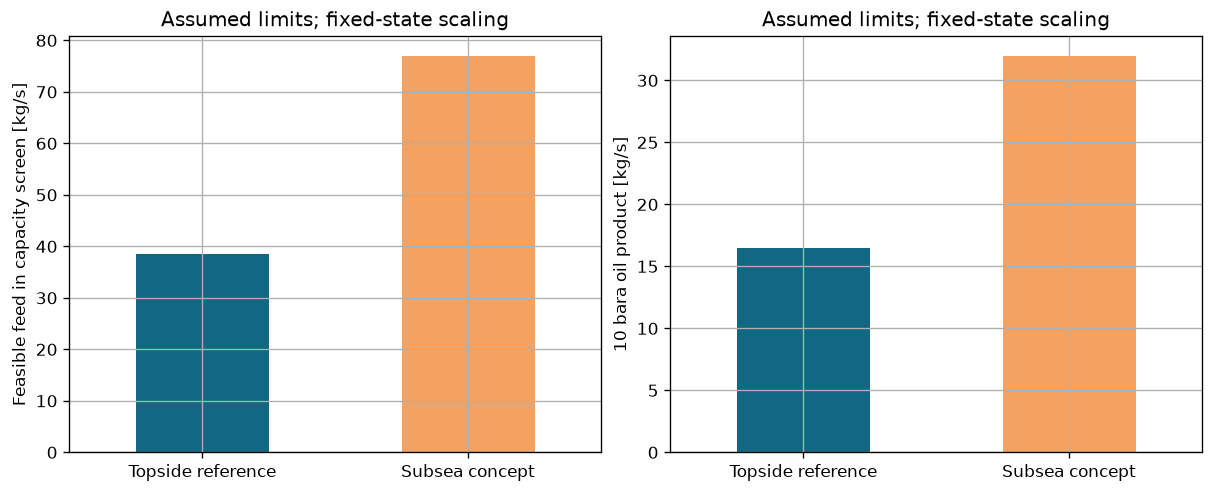

In [9]:
LIMITS = {
    "host_gas_kg_s": 22.0,
    "electrical_MW": 6.0,
    "oil_product_kg_s": 40.0,
    "reinjection_kg_s": 45.0,
}
capacity_rows = []
for case_name, row in summary.iterrows():
    scales = {key: limit / row[key] for key, limit in LIMITS.items()}
    limiting_constraint = min(scales, key=scales.get)
    scale = scales[limiting_constraint]
    capacity_rows.append({
        "case": case_name, "throughput_multiplier": scale,
        "feed_kg_s": row["feed_kg_s"] * scale,
        "oil_product_kg_s": row["oil_product_kg_s"] * scale,
        "electrical_MW": row["electrical_MW"] * scale,
        "limiting_constraint": limiting_constraint,
    })
capacity_table = pd.DataFrame(capacity_rows).set_index("case")
display(pd.DataFrame({"assumed_limit": LIMITS}))
display(capacity_table.round(4))

replay_settings = dict(CASE)
replay_settings["feed_kg_s"] = float(capacity_table.loc["Subsea concept", "feed_kg_s"])
replay = summarize(build_process(True, replay_settings))
for variable, limit in LIMITS.items():
    assert replay[variable] <= limit * (1.0 + 1e-6)
    scaled_value = summary.loc["Subsea concept", variable] * capacity_table.loc[
        "Subsea concept", "throughput_multiplier"
    ]
    assert np.isclose(replay[variable], scaled_value, rtol=1e-5)
print("PASS: native replay of the limiting subsea feed")
gravity_scale_MW = summary.loc["Topside reference", "reinjection_kg_s"] * 9.80665 * 2000 / 1e6
print("Illustrative 2,000 m reinjection gravitational-energy scale [MW]:",
      round(gravity_scale_MW, 4))
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
capacity_table["feed_kg_s"].plot.bar(ax=axes[0], rot=0, color=["#126782", "#f4a261"])
capacity_table["oil_product_kg_s"].plot.bar(ax=axes[1], rot=0, color=["#126782", "#f4a261"])
axes[0].set_ylabel("Feasible feed in capacity screen [kg/s]")
axes[1].set_ylabel("10 bara oil product [kg/s]")
for axis in axes:
    axis.set_xlabel("")
    axis.set_title("Assumed limits; fixed-state scaling")
plt.show()

## 9. Independent property check and EOS sensitivity

For pure CO₂, CoolProp's HEOS backend uses the Span–Wagner reference EOS [R5, R6]. The following density comparison is independent of NeqSim's cubic implementation. Its scope is **pure CO₂ at the tabulated states**; it does not validate the multicomponent oil mixture, phase split, or a vendor pump.

The PR–SRK comparison then measures model-form sensitivity for the synthetic process. Differences remain visible; parameters are not fitted to force agreement.

,temperature_C,pressure_bara,NeqSim_PR_density_kg_m3,Span_Wagner_density_kg_m3,relative_difference_percent
0,25.0,150.0,867.5924,876.4729,-1.0132
1,25.0,200.0,922.8615,914.2367,0.9434
2,25.0,300.0,997.7289,966.5172,3.2293
3,60.0,150.0,560.9491,604.0922,-7.1418
4,60.0,200.0,693.9465,723.6820,-4.1089
5,60.0,300.0,831.1264,829.7135,0.1703


,bypass_kg_s,CO2_bypass_fraction,electrical_MW,oil_product_kg_s
EOS,,,,
PR,18.60624,0.59579,3.34574,20.76663
SRK,17.96680,0.57691,3.59147,20.96744


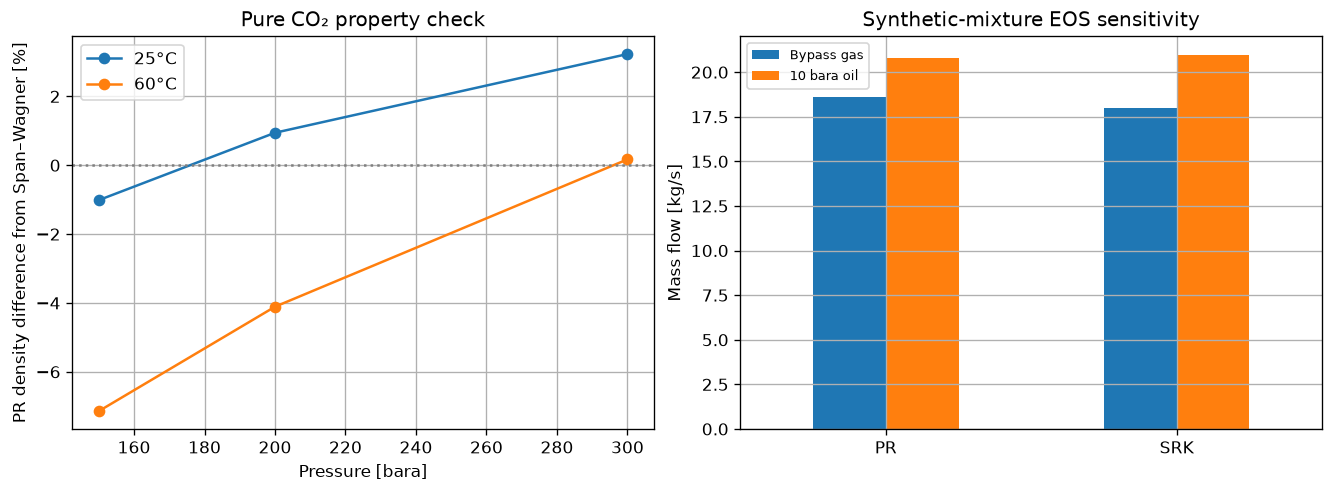

In [10]:
property_rows = []
for temperature in (25.0, 60.0):
    for pressure in (150.0, 200.0, 300.0):
        pure_co2 = make_fluid(temperature, pressure, {"CO2": 1.0})
        ThermodynamicOperations(pure_co2).TPflash()
        pure_co2.initProperties()
        cubic_density = pure_co2.getDensity("kg/m3")
        reference_density = PropsSI("Dmass", "T", temperature + 273.15,
                                    "P", pressure * 1e5, "HEOS::CO2")
        property_rows.append({
            "temperature_C": temperature, "pressure_bara": pressure,
            "NeqSim_PR_density_kg_m3": cubic_density,
            "Span_Wagner_density_kg_m3": reference_density,
            "relative_difference_percent": 100 * (cubic_density / reference_density - 1),
        })
property_comparison = pd.DataFrame(property_rows)
assert np.isfinite(property_comparison.select_dtypes("number")).all().all()
assert property_comparison["relative_difference_percent"].abs().max() < 15.0
display(property_comparison.round(4))

srk_subsea = build_process(True, eos="SRK")
eos_comparison = pd.DataFrame([
    {"EOS": "PR", **summarize(subsea)},
    {"EOS": "SRK", **summarize(srk_subsea)},
]).set_index("EOS")
display(eos_comparison[["bypass_kg_s", "CO2_bypass_fraction", "electrical_MW",
                        "oil_product_kg_s"]].round(5))
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for temperature, group in property_comparison.groupby("temperature_C"):
    axes[0].plot(group["pressure_bara"], group["relative_difference_percent"],
                 "o-", label=f"{temperature:g}°C")
axes[0].axhline(0, color="0.5", linestyle=":")
axes[0].set_xlabel("Pressure [bara]")
axes[0].set_ylabel("PR density difference from Span–Wagner [%]")
axes[0].legend()
axes[0].set_title("Pure CO₂ property check")
eos_comparison[["bypass_kg_s", "oil_product_kg_s"]].plot.bar(ax=axes[1], rot=0)
axes[1].set_ylabel("Mass flow [kg/s]")
axes[1].set_xlabel("")
axes[1].legend(["Bypass gas", "10 bara oil"], fontsize=8)
axes[1].set_title("Synthetic-mixture EOS sensitivity")
plt.show()

## 10. Engineering interpretation and reusable results

The key distinction is between **gas routed away from topside**, **total reinjection**, and **CO₂ avoided emissions**. This model calculates the first two. Avoided emissions require a baseline fuel/power supply, operating hours, methane handling and a complete energy boundary. Reservoir recovery and production acceleration require coupled reservoir forecasts.

Qualification achieved here: ordered native process execution, total/component balances, energy closure, an isentropic work identity/integration check, nearby-state sweeps, a native capacity replay, and a bounded independent pure-CO₂ density comparison. The synthetic mixture remains uncalibrated to laboratory PVT.

For detailed engineering, supply an assay/PVT-tuned EOS; water/salt/MEG data; separator carryover and kinetics; dense-gas pump maps and phase-margin limits; seawater cooling/UA/fouling data; riser/injection-line/well hydraulics; availability and trip requirements; and reservoir injectivity/compositional response. Existing NeqSim streams and `ProcessSystem` objects in this notebook provide the coupling boundary.

In [11]:
base = summary.loc["Topside reference"]
concept = summary.loc["Subsea concept"]
host_reduction = 100 * (1 - concept["host_gas_kg_s"] / base["host_gas_kg_s"])
processing_power_change = concept["electrical_MW"] - base["electrical_MW"]
conclusion = f"""
**Calculated synthetic case:** subsea gas bypass is **{concept['bypass_kg_s']:.2f} kg/s**,
which routes **{100 * concept['CO2_bypass_fraction']:.1f}%** of feed CO₂ directly to reinjection.
Topside separated-gas load changes by **{host_reduction:.1f}%**.
The electrical processing duty changes from **{base['electrical_MW']:.3f} MW** to
**{concept['electrical_MW']:.3f} MW** (concept minus reference:
**{processing_power_change:+.3f} MW**).

The oil product changes from **{base['oil_product_kg_s']:.2f}** to
**{concept['oil_product_kg_s']:.2f} kg/s** at fixed feed. This includes hydrocarbon partitioning;
it is not an oil-recovery-factor prediction.
The separate capacity screen uses its own stated limits.
"""
display(Markdown(conclusion))

output_directory = Path("hisep_screening_results")
output_directory.mkdir(exist_ok=True)
export_tables = {
    "case_summary": summary,
    "stream_states": stream_table,
    "component_partition": partition_table,
    "balance_validation": validation_table,
    "separation_pressure_temperature": separation_sweep,
    "pump_sensitivity": pump_sensitivity,
    "capacity_screen": capacity_table,
    "pure_co2_property_comparison": property_comparison,
    "eos_sensitivity": eos_comparison,
}
for name, table in export_tables.items():
    table.to_csv(output_directory / f"{name}.csv", index=True)
run_record = {
    "notebook_version": "1.0.0", "source_commit": source_sha,
    "source_jar_sha256": jar_sha256, "build_method": build_method,
    "case": CASE, "composition": COMPOSITION,
    "scope": "Dry synthetic steady-state processing block; no reservoir/vertical hydraulics",
    "checks": {
        "mass_and_component_balance": True, "energy_balance": True,
        "pump_integral_relative_error": float(integral_relative_error),
        "pump_enthalpy_relative_error": float(pump_relative_error),
        "pure_CO2_max_density_difference_percent": float(
            property_comparison["relative_difference_percent"].abs().max()
        ),
        "native_capacity_replay": True,
    },
}
(output_directory / "run_record.json").write_text(json.dumps(run_record, indent=2))
print("Reusable Java models: reference['process'] and subsea['process']")
print("Named boundary streams: ['feed'], ['oil'], ['injection'], ['bypass_gas']")
print("Saved result tables:", ", ".join(export_tables))
print("PASS: all displayed checks completed; see stated qualification scope")

Reusable Java models: reference['process'] and subsea['process']
Named boundary streams: ['feed'], ['oil'], ['injection'], ['bypass_gas']
Saved result tables: case_summary, stream_states, component_partition, balance_validation, separation_pressure_temperature, pump_sensitivity, capacity_screen, pure_co2_property_comparison, eos_sensitivity
PASS: all displayed checks completed; see stated qualification scope



**Calculated synthetic case:** subsea gas bypass is **18.61 kg/s**,
which routes **59.6%** of feed CO₂ directly to reinjection.
Topside separated-gas load changes by **62.8%**.
The electrical processing duty changes from **6.376 MW** to
**3.346 MW** (concept minus reference:
**-3.030 MW**).

The oil product changes from **21.43** to
**20.77 kg/s** at fixed feed. This includes hydrocarbon partitioning;
it is not an oil-recovery-factor prediction.
The separate capacity screen uses its own stated limits.


## 11. Open references and further work

**R1.** TechnipFMC (2024). [Inside HISEP — taking dense-gas separation and storage fully subsea](https://www.technipfmc.com/en/media/news/2024/03/inside-hisep-how-technipfmc-is-taking-dense-gas-separation-and-storage-fully-subsea/). Public process/equipment description; no proprietary design data used.

**R2.** Sulzer (4 June 2024). [Sulzer supports TechnipFMC on innovative CO₂ pumps for subsea oil and gas separation](https://www.sulzer.com/en/shared/news/240604-sulzer-supports-technipfmc-on-innovative-co2-pumps-for-subsea-oil-and-gas-separation). Public dense-gas pumping context; reported 6 MW ratings are not notebook predictions.

**R3.** *Evaluating High-Pressure Subsea Separation for Improving Field Development and Gas Management in Pre-Salt Brazilian Reservoirs* (ROG.e 2024). [DOI: 10.48072/2525-7579.roge.2024.2792](https://doi.org/10.48072/2525-7579.roge.2024.2792); [public author-uploaded text](https://www.researchgate.net/publication/384361997_Evaluating_High-Pressure_Subsea_Separation_for_Improving_Field_Development_and_Gas_Management_in_Pre-Salt_Brazilian_Reservoirs). Reservoir/production-management motivation; its field forecasts are outside this notebook.

**R4.** Petrobras (20 August 2026). [Mero update describing HISEP as under qualification](https://agencia.petrobras.com.br/w/negocio/navio-plataforma-alexandre-de-gusm%C3%A3o-atinge-topo-de-produ%C3%A7%C3%A3o-no-pr%C3%A9-sal). Status checked when preparing this example.

**R5.** Span, R. and Wagner, W. (1996). *A New Equation of State for Carbon Dioxide Covering the Fluid Region from the Triple-Point Temperature to 1100 K at Pressures up to 800 MPa*. [DOI: 10.1063/1.555991](https://doi.org/10.1063/1.555991). Reference property formulation implemented by CoolProp.

**R6.** Bell, I. H. et al. (2014). *Pure and Pseudo-pure Fluid Thermophysical Property Evaluation and the Open-Source Thermophysical Property Library CoolProp*. [DOI: 10.1021/ie4033999](https://doi.org/10.1021/ie4033999); [open documentation](https://coolprop.org/fluid_properties/fluids/CarbonDioxide.html).

**Related open study:** Jing et al. (2024), [Study on Dense Phase Separation of Associated Gas with High Carbon Dioxide Content](https://doi.org/10.3390/pr12122924), *Processes* 12, 2924. Its cryogenic multistage CO₂/CH₄ separation objective differs from high-pressure oil/associated-gas separation and reinjection. Its reported separation efficiency is not a benchmark for this flowsheet.

**Exercises:** replace the synthetic fluid with public measured PVT; add finite separator efficiency and a water-management model; connect riser and injection-well hydraulics; use vendor pump/compressor maps; couple time-dependent injection composition to a reservoir model; and compare throughput under equipment availability constraints.

**Documentation impact:** this notebook, the repository catalog, README and a dedicated maintenance-ledger shard describe the new educational workflow. No Java API changes are required for this screening model. Detailed equipment qualification and field validation remain outside the demonstrated evidence.